# Homework 04: Advanced Regression and Logistic Regression

**Course:** CPE 486/586 - Fall 2026  
**Name:** Rudaina Tasnuva  
**UAH Email:** [rt1744@uah.edu]  
**Unique Package Keyword:** bobatea5156  
**GitHub Repository:** [https://github.com/bobatea5156gh/bobatea5156]

## Problem 5: Multiple Regression

In this problem, I will develop a multiple linear regression model to predict the net hourly electrical energy output (PE) of a combined-cycle power plant.

The dataset contains 9,568 observations and four input features:

- **AT:** Ambient temperature (°C)
- **V:** Exhaust vacuum (cm Hg)
- **AP:** Ambient pressure (millibar)
- **RH:** Relative humidity (%)

The target variable is **PE**, which represents electrical power output in MW.

The regression model will be trained using the Cauchy loss function, implemented with PyTorch.

### 1. Importing Required Libraries

I will use NumPy and pandas for data handling, Matplotlib and Seaborn for visualization, and PyTorch to implement and train the regression model.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

print("Libraries imported successfully!")


Libraries imported successfully!


### 2. Loading and Exploring the Dataset

The dataset is loaded into a pandas DataFrame. I will first check its dimensions, column names, and sample observations to confirm that it contains the required variables.

In [3]:

from google.colab import files

uploaded = files.upload()


Saving Folds5x2_pp.csv to Folds5x2_pp (1).csv


In [4]:

import io

filename = next(iter(uploaded))

if filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
elif filename.endswith(".csv"):
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
else:
    raise ValueError(f"Unsupported file format: {filename}")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())


Dataset shape: (9568, 5)

Column names: ['AT', 'V', 'AP', 'RH', 'PE']


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


### 3. Scatterplot Matrix

To understand the relationships among the variables, I will create a scatterplot matrix containing the four input features (AT, V, AP, RH) and the target variable (PE).

The scatterplots will help identify possible linear or nonlinear relationships, while also showing whether any of the predictors appear strongly correlated with each other.

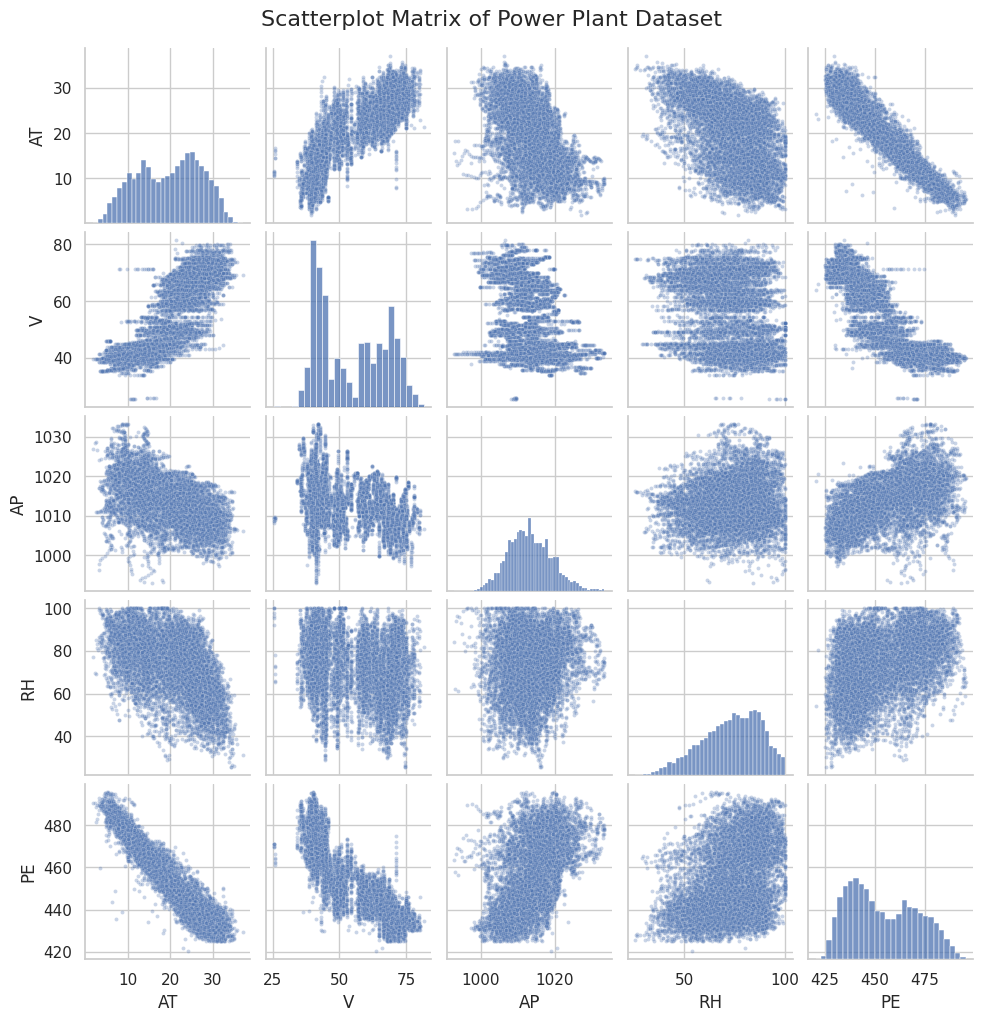

In [25]:


columns = ["AT", "V", "AP", "RH", "PE"]

sns.set_theme(style="whitegrid")

g = sns.pairplot(
    df[columns],
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 8},
    height=2
)

g.fig.suptitle(
    "Scatterplot Matrix of Power Plant Dataset",
    fontsize=16,
    y=1.02
)

plt.savefig(
    "scatterplot_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of the Scatterplot Matrix

The scatterplot matrix shows the relationships among the four input features and the electrical power output (PE).

From the plots, ambient temperature (AT) appears to have a strong negative relationship with power output, meaning that higher temperatures are generally associated with lower power generation. Exhaust vacuum (V) also appears to be negatively related to PE, while ambient pressure (AP) shows a weaker positive relationship. The relationship between relative humidity (RH) and PE is less obvious.

Among the input features, AT and V appear positively correlated, while AT and RH show a negative relationship. These correlations are useful to consider when building the multiple regression model, since strongly related predictors may affect the stability of the estimated coefficients.

Overall, the scatterplot matrix provides an initial understanding of the dataset before fitting the regression model.

## Multiple Linear Regression Using Cauchy Loss

The goal is to predict electrical power output (PE) using ambient temperature (AT), exhaust vacuum (V), ambient pressure (AP), and relative humidity (RH).

The regression model is

$$
\hat{y} = w_0 + w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4
$$

Instead of the usual mean squared error, I will use the Cauchy loss function to train the model. This loss is less sensitive to large prediction errors, making it useful when the dataset contains outliers.

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select the four input features and target
X = df[["AT", "V", "AP", "RH"]].values
y = df["PE"].values

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize the input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert arrays into PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)
X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test, dtype=torch.float32
).reshape(-1, 1)

print("Training samples:", X_train_tensor.shape)
print("Testing samples:", X_test_tensor.shape)


Training samples: torch.Size([7654, 4])
Testing samples: torch.Size([1914, 4])


### Implementing the CauchyRegression Class

I will create a custom 'CauchyRegression' class using PyTorch. The class will contain the regression coefficients, a prediction method, the Cauchy loss function, and a training method.

The model will learn its parameters by minimizing the average Cauchy loss using gradient-based optimization.

In [15]:

import torch
import torch.nn as nn

class CauchyRegression(nn.Module):
    def __init__(self, n_features, c=1.0):
        super().__init__()

        # Linear regression model with intercept
        self.linear = nn.Linear(n_features, 1)

        # Cauchy loss scale parameter
        if c <= 0:
            raise ValueError("c must be positive")
        self.c = float(c)

    def forward(self, X):
        # Predict electrical power output
        return self.linear(X)

    def cauchy_loss(self, y_pred, y_true):
        # Calculate average Cauchy loss
        residual = y_true - y_pred

        loss = (self.c ** 2 / 2) * torch.log1p(
            (residual / self.c) ** 2
        )

        return torch.mean(loss)

    def fit(self, X, y, epochs=2000, lr=0.01):
        # Train the regression model
        optimizer = torch.optim.Adam(
            self.parameters(), lr=lr
        )

        self.loss_history = []

        for epoch in range(epochs):
            optimizer.zero_grad()

            y_pred = self.forward(X)
            loss = self.cauchy_loss(y_pred, y)

            loss.backward()
            optimizer.step()

            self.loss_history.append(loss.item())

            if (epoch + 1) % 200 == 0:
                print(
                    f"Epoch {epoch+1}/{epochs}, "
                    f"Loss: {loss.item():.4f}"
                )

        return self

    def predict(self, X):
        # Predict without tracking gradients
        self.eval()

        with torch.no_grad():
            return self.forward(X)


### Training the Cauchy Regression Model

After defining the regression class, I will train the model using the training dataset. The model parameters will be updated using the Adam optimizer to minimize the Cauchy loss.

I will initialize the intercept using the average training target value and monitor the loss during training to check whether the model is learning.

In [19]:

# Set random seed for reproducibility
torch.manual_seed(42)

# Create the regression model
model = CauchyRegression(n_features=4, c=1.0)

# Initialize the weights and intercept
with torch.no_grad():
    model.linear.weight.zero_()
    model.linear.bias.fill_(y_train_tensor.mean().item())

# Train the model
model.fit(
    X_train_tensor,
    y_train_tensor,
    epochs=2000,
    lr=0.01
)


Epoch 200/2000, Loss: 1.9817
Epoch 400/2000, Loss: 1.5632
Epoch 600/2000, Loss: 1.4151
Epoch 800/2000, Loss: 1.3362
Epoch 1000/2000, Loss: 1.2729
Epoch 1200/2000, Loss: 1.2240
Epoch 1400/2000, Loss: 1.2023
Epoch 1600/2000, Loss: 1.1864
Epoch 1800/2000, Loss: 1.1740
Epoch 2000/2000, Loss: 1.1641


CauchyRegression(
  (linear): Linear(in_features=4, out_features=1, bias=True)
)

### Training Loss

To observe the training process, I plotted the Cauchy loss against the number of epochs. This helps show whether the optimization algorithm is reducing the loss as the model learns its parameters.

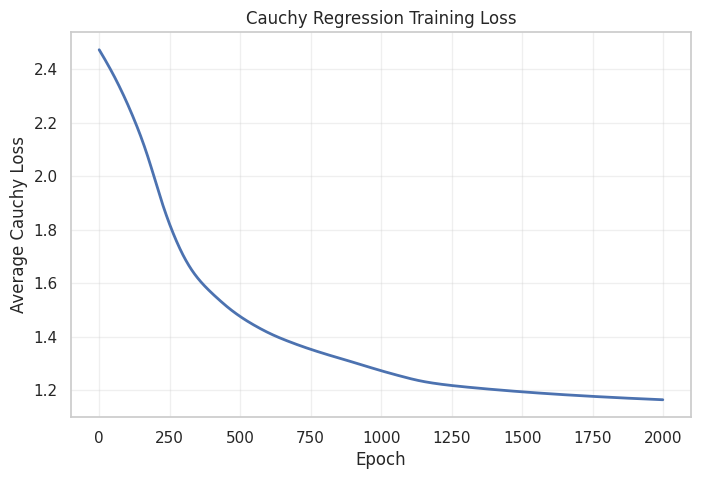

In [18]:

# Plot Cauchy loss during training
plt.figure(figsize=(8, 5))

plt.plot(model.loss_history, linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Average Cauchy Loss")
plt.title("Cauchy Regression Training Loss")
plt.grid(True, alpha=0.3)

plt.savefig(
    "cauchy_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# Display learned parameters
weights = model.linear.weight.detach().numpy().flatten()
bias = model.linear.bias.detach().item()

print(f"Intercept (scaled model): {bias:.4f}")

for feature, weight in zip(["AT", "V", "AP", "RH"], weights):
    print(f"{feature} coefficient: {weight:.4f}")


Intercept (scaled model): 454.2675
AT coefficient: -12.1284
V coefficient: -5.5118
AP coefficient: 0.6013
RH coefficient: -1.2651


### Model Evaluation

After training the model, I evaluated its performance using the test dataset, which was not used during training.

I used Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²) to measure prediction accuracy. Lower MAE and RMSE values indicate smaller prediction errors, while an R² value closer to 1 indicates a better fit.

In [21]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate predictions on the test dataset
y_pred_tensor = model.predict(X_test_tensor)

# Convert predictions to NumPy arrays
y_pred = y_pred_tensor.numpy().flatten()
y_actual = y_test_tensor.numpy().flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")


Mean Absolute Error (MAE): 3.6757
Root Mean Squared Error (RMSE): 4.6285
R-squared (R²): 0.9251


### Interpretation of Model Performance

The Cauchy regression model, trained with \(c=1\), achieved an MAE of 3.6757 MW, an RMSE of 4.6285 MW, and an R² value of 0.9251 on the test dataset.

The MAE indicates that the predicted electrical power output differs from the actual output by approximately 3.68 MW on average. The RMSE of 4.6285 MW shows that the model has relatively small prediction errors, although some predictions may differ more than others.

The R² value indicates that the model explains approximately 92.51% of the variation in electrical power output on the test data.

Overall, these results suggest that the Cauchy regression model provides a good fit and predicts electrical power output reasonably accurately using the four input features.

In [23]:

# Convert standardized coefficients to original units

scaled_weights = model.linear.weight.detach().numpy().flatten()
scaled_intercept = model.linear.bias.detach().item()

# Undo feature standardization
original_weights = scaled_weights / scaler.scale_

original_intercept = (
    scaled_intercept
    - np.sum(original_weights * scaler.mean_)
)

feature_names = ["AT", "V", "AP", "RH"]

print(f"Original intercept (w0): {original_intercept:.4f}")

for i, feature in enumerate(feature_names):
    print(
        f"{feature} coefficient (w{i+1}): "
        f"{original_weights[i]:.4f}"
    )

print("\nFinal regression equation:")
print(
    f"PE = {original_intercept:.4f}"
    + "".join(
        f" {w:+.4f}*{name}"
        for w, name in zip(original_weights, feature_names)
    )
)


Original intercept (w0): 412.9500
AT coefficient (w1): -1.6233
V coefficient (w2): -0.4335
AP coefficient (w3): 0.1018
RH coefficient (w4): -0.0868

Final regression equation:
PE = 412.9500 -1.6233*AT -0.4335*V +0.1018*AP -0.0868*RH


### Final Regression Equation and Interpretation

After training the multiple linear regression model using the Cauchy loss function with \(c=1\), I converted the learned coefficients back to their original feature units.

The resulting regression equation is:

$$
\widehat{PE} = 412.9500 - 1.6233AT - 0.4335V + 0.1018AP - 0.0868RH
$$

The coefficient of ambient temperature (AT) is negative, indicating that a 1°C increase in temperature is associated with an approximately 1.6233 MW decrease in predicted power output, assuming the other variables remain constant.

Exhaust vacuum (V) and relative humidity (RH) also have negative coefficients, suggesting that higher values of these variables are associated with slightly lower power output.

Ambient pressure (AP) has a positive coefficient, indicating that increasing atmospheric pressure is associated with a small increase in predicted power output when the other variables are held constant.

Overall, the fitted model shows how the four environmental factors contribute to predicting electrical power generation.

### 4. Final Cauchy Loss

To evaluate the training process, I calculated the final average Cauchy loss after training the regression model with \(c=1\).

The Cauchy loss function is:

$$
\ell(\hat{y},y)=\frac{1}{2}\log\left(1+(y-\hat{y})^2\right)
$$

The final loss is calculated by averaging this expression over all training observations. A lower loss indicates that the model's predictions are closer to the actual values according to the Cauchy loss function.

In [26]:


model.eval()

with torch.no_grad():
    train_pred = model(X_train_tensor)
    final_train_loss = model.cauchy_loss(
        train_pred, y_train_tensor
    ).item()

    test_pred = model(X_test_tensor)
    final_test_loss = model.cauchy_loss(
        test_pred, y_test_tensor
    ).item()

print(f"Final Training Loss: {final_train_loss:.4f}")
print(f"Final Testing Loss: {final_test_loss:.4f}")


Final Training Loss: 1.1641
Final Testing Loss: 1.1477


### Interpretation of Final Cauchy Loss

After training the model using the Cauchy loss function with \(c=1\), the final average training loss was **1.1641**, while the testing loss was **1.1477**.

The training loss decreased during optimization, showing that the model was learning the relationship between the input features and electrical power output. The testing loss is close to the training loss, suggesting that the model performs similarly on unseen data.

Overall, the results indicate that the model has learned a useful relationship between the four input variables and power output.

### 5. 95% Confidence Intervals for Regression Coefficients

I calculated approximate 95% confidence intervals for the regression coefficients using the fitted Cauchy regression model in Statsmodels.

The confidence intervals for ambient temperature (AT), exhaust vacuum (V), and relative humidity (RH) are entirely negative and do not include zero. This suggests that these three variables have statistically significant negative relationships with electrical power output, after accounting for the other predictors.

On the other hand, the confidence interval for ambient pressure (AP) ranges from -0.0143 to 0.0218 and includes zero. Therefore, there is not enough statistical evidence to conclude that ambient pressure has a significant effect on power output at the 5% significance level.

Overall, the confidence intervals suggest that temperature, exhaust vacuum, and relative humidity are important predictors, while the contribution of ambient pressure is less certain.

In [34]:

# 5. Approximate 95% confidence intervals
# Using the converged Statsmodels Cauchy regression

import numpy as np
import pandas as pd
from scipy.stats import norm

# Estimated parameters and covariance matrix
params = np.asarray(result_sm.params)
cov_scaled = np.asarray(result_sm.cov_params())

# Transformation from standardized to original units
transform = np.zeros((5, 5))
transform[0, 0] = 1.0

for j in range(4):
    transform[0, j + 1] = (
        -scaler.mean_[j] / scaler.scale_[j]
    )
    transform[j + 1, j + 1] = 1.0 / scaler.scale_[j]

# Original-unit coefficients and covariance
params_original = transform @ params
cov_original = transform @ cov_scaled @ transform.T

# Standard errors
standard_errors = np.sqrt(np.diag(cov_original))

# 95% confidence intervals
z = norm.ppf(0.975)

ci_lower = params_original - z * standard_errors
ci_upper = params_original + z * standard_errors

ci_table = pd.DataFrame({
    "Coefficient": ["Intercept", "AT", "V", "AP", "RH"],
    "Estimate": params_original,
    "95% CI Lower": ci_lower,
    "95% CI Upper": ci_upper
})

display(ci_table.round(4))



,Coefficient,Estimate,95% CI Lower,95% CI Upper
0,Intercept,515.1027,496.4967,533.7088
1,AT,-2.0758,-2.1079,-2.0437
2,V,-0.2368,-0.2510,-0.2226
3,AP,0.0037,-0.0143,0.0218
4,RH,-0.1524,-0.1606,-0.1442


### 6. Residual Analysis

To examine how well the Cauchy regression model fits the data, I plotted the residuals against each of the four input features.

The residual is calculated as:

$$
e_i = \hat{y}_i-y_i
$$

where \(\hat{y}_i\) is the predicted electrical power output and \(y_i\) is the actual output.

Ideally, residuals should be randomly scattered around zero without any clear pattern. A curved pattern may indicate that the linear model does not capture all the relationships in the data, while a changing spread may suggest non-constant error variance.

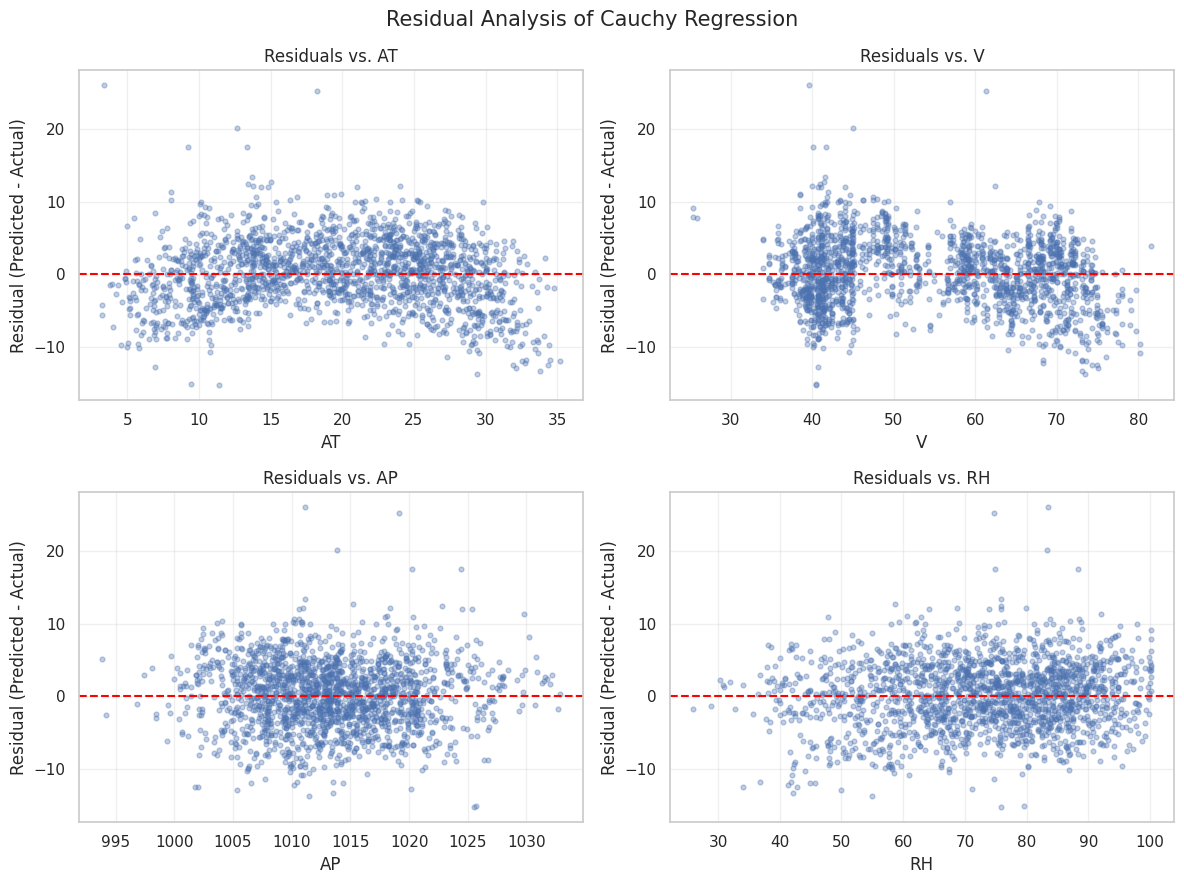

In [28]:

# Question 6: Residual plots for all four features

# Generate predictions from the trained model (c = 1)
model.eval()

with torch.no_grad():
    predictions = model(X_test_tensor).cpu().numpy().flatten()

# Residuals: predicted - actual
residuals = predictions - y_test

# Original (unscaled) test features
feature_names = ["AT", "V", "AP", "RH"]

# Create four residual plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, ax in enumerate(axes.flatten()):
    ax.scatter(
        X_test[:, i],
        residuals,
        alpha=0.35,
        s=12
    )

    ax.axhline(
        y=0,
        color="red",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_xlabel(feature_names[i])
    ax.set_ylabel("Residual (Predicted - Actual)")
    ax.set_title(
        f"Residuals vs. {feature_names[i]}"
    )

    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Residual Analysis of Cauchy Regression",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "cauchy_residual_plots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of Residual Plots

The residual plots show how the prediction errors vary with ambient temperature (AT), exhaust vacuum (V), ambient pressure (AP), and relative humidity (RH).

For ambient temperature and exhaust vacuum, some patterns and clustering are visible, suggesting that the linear regression model may not capture all the relationships in the data. The residuals for ambient pressure are more randomly scattered around zero, although a few large errors can be observed.

For relative humidity, the residuals are also distributed around zero, but their spread changes slightly across different humidity values. This may indicate some variation in the error variance.

Overall, most residuals are concentrated near zero, which suggests that the model provides a reasonable fit. However, the visible patterns and outliers indicate that some nonlinear relationships or other effects may not be fully captured by the linear model.

### 7. Alternative Cauchy Regression Using Statsmodels

As an alternative to the PyTorch implementation, I implemented Cauchy regression using the 'GenericLikelihoodModel'  class from Statsmodels.

The model uses the same four input features and predicts electrical power output using a linear equation. I used a fixed Cauchy scale parameter of \(c=1\), consistent with the previous implementation.

The parameters are estimated by maximizing the Cauchy log-likelihood, which is equivalent to minimizing the Cauchy loss for a fixed scale parameter.

In [29]:

import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel

print("Statsmodels imported successfully!")


Statsmodels imported successfully!


In [30]:

# Alternative Cauchy regression using Statsmodels

class CauchyModel(GenericLikelihoodModel):

    def __init__(self, endog, exog, c=1.0, **kwargs):
        if c <= 0:
            raise ValueError("c must be positive")

        self.c = float(c)
        super().__init__(endog, exog, **kwargs)

    def nloglikeobs(self, params):
        # Linear predictions
        y_pred = self.exog @ params

        # Residuals
        residuals = self.endog - y_pred

        # Cauchy negative log-likelihood
        # Constant terms do not affect the fitted coefficients
        return np.log1p((residuals / self.c) ** 2)

    def predict(self, params, exog=None):
        if exog is None:
            exog = self.exog

        return np.asarray(exog) @ params


In [31]:

# Add intercept column
X_train_sm = sm.add_constant(
    X_train_scaled, has_constant="add"
)

X_test_sm = sm.add_constant(
    X_test_scaled, has_constant="add"
)

# Initialize with the trained PyTorch parameters
start_params = np.concatenate([
    [model.linear.bias.detach().item()],
    model.linear.weight.detach().numpy().flatten()
])

# Create Statsmodels Cauchy model
cauchy_sm = CauchyModel(
    y_train,
    X_train_sm,
    c=1.0
)

# Fit using BFGS optimization
result_sm = cauchy_sm.fit(
    start_params=start_params,
    method="bfgs",
    maxiter=2000,
    disp=False
)

print("Optimization converged:",
      result_sm.mle_retvals.get("converged"))

print("\nFitted parameters (standardized inputs):")
print(result_sm.params)


Optimization converged: True

Fitted parameters (standardized inputs):
[ 4.54024424e+02 -1.55093345e+01 -3.01031165e+00  2.19568924e-02
 -2.21974063e+00]


In [32]:

# Convert Statsmodels coefficients to original units

sm_weights_scaled = result_sm.params[1:]
sm_bias_scaled = result_sm.params[0]

sm_weights_original = (
    sm_weights_scaled / scaler.scale_
)

sm_intercept_original = (
    sm_bias_scaled
    - np.sum(sm_weights_original * scaler.mean_)
)

print(f"Intercept: {sm_intercept_original:.4f}")

for name, weight in zip(
    ["AT", "V", "AP", "RH"],
    sm_weights_original
):
    print(f"{name}: {weight:.4f}")

print("\nStatsmodels regression equation:")
print(
    f"PE = {sm_intercept_original:.4f}"
    + "".join(
        f" {w:+.4f}*{name}"
        for w, name in zip(
            sm_weights_original,
            ["AT", "V", "AP", "RH"]
        )
    )
)


Intercept: 515.1027
AT: -2.0758
V: -0.2368
AP: 0.0037
RH: -0.1524

Statsmodels regression equation:
PE = 515.1027 -2.0758*AT -0.2368*V +0.0037*AP -0.1524*RH


In [33]:

# Check convergence and compare the two implementations

print("Statsmodels converged:",
      result_sm.mle_retvals.get("converged"))

# Statsmodels predictions on the training set
sm_train_pred = result_sm.predict(X_train_sm)

# PyTorch predictions on the training set
with torch.no_grad():
    torch_train_pred = (
        model(X_train_tensor).cpu().numpy().flatten()
    )

# Calculate the same Cauchy loss for both models (c = 1)
def average_cauchy_loss(y_true, y_pred):
    return 0.5 * np.mean(
        np.log1p((y_true - y_pred) ** 2)
    )

print("\nAverage Training Cauchy Loss:")
print(
    f"PyTorch: "
    f"{average_cauchy_loss(y_train, torch_train_pred):.4f}"
)
print(
    f"Statsmodels: "
    f"{average_cauchy_loss(y_train, sm_train_pred):.4f}"
)


Statsmodels converged: True

Average Training Cauchy Loss:
PyTorch: 1.1641
Statsmodels: 1.1401


### Interpretation of Statsmodels Cauchy Regression

I implemented an alternative Cauchy regression model using the `GenericLikelihoodModel` class from Statsmodels, with the Cauchy scale parameter fixed at \(c=1\).

The fitted regression equation is:

$$
\widehat{PE} = 515.1027 - 2.0758AT - 0.2368V + 0.0037AP - 0.1524RH
$$

The Statsmodels optimizer converged successfully and achieved an average training Cauchy loss of **1.1401**, compared with **1.1641** for the PyTorch implementation.

Both models use the same linear regression equation and Cauchy loss objective, but they use different optimization methods. The slightly lower loss obtained with Statsmodels suggests that it found a better solution for the training data.

Overall, the Statsmodels implementation provides an alternative way to estimate the regression coefficients using maximum likelihood estimation.